# E-Commerce Product Analytics

## Web Scraping Using Python and BeautifulSoup

### Project Objective

The objective of this project is to collect e-commerce product data from the Books to Scrape website using Python and BeautifulSoup. The scraped data will be structured and stored in a CSV file for further data cleaning, exploratory data analysis, statistical analysis, MySQL database storage, and Power BI dashboard development.

### Tools and Technologies

- Python
- Requests
- BeautifulSoup
- Pandas
- MySQL
- Power BI

### Data Source

Books to Scrape: https://books.toscrape.com/

### Data Fields

The project aims to collect relevant product information such as:

- Product Name
- Price
- Rating
- Availability
- Product Category
- UPC
- Product Description


## 1. Import Required Libraries

The following Python libraries are used for web scraping and data handling:

- **Requests:** Used to send HTTP requests and retrieve webpage content.
- **BeautifulSoup:** Used to parse HTML and extract required information from webpages.
- **Pandas:** Used to organize scraped data into a DataFrame and save it as a CSV file.
- **Time:** Used to introduce a short delay between requests.

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

## 2. Connect to the Website

The Books to Scrape website is used as the data source for this project. The `requests` library is used to send an HTTP request to the website and retrieve its HTML content.

A status code of 200 indicates that the webpage was successfully retrieved.

In [4]:
url = "https://books.toscrape.com/"

response = requests.get(url)

print(response.status_code)

200


## 3. Parse the HTML Using BeautifulSoup

BeautifulSoup is used to parse the HTML content returned by the website. This allows us to identify and extract specific elements containing product information.

In [5]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)


    All products | Books to Scrape - Sandbox



## 4. Identify Products on the Webpage

Each book on the webpage is contained within an HTML `article` element with the class `product_pod`. BeautifulSoup is used to locate all such elements.

In [6]:
books = soup.find_all("article", class_="product_pod")

print(len(books))

20


## 5. Extract Product Information

Before scraping all products, the first book is examined to understand the HTML structure and verify that the required product fields can be extracted correctly.

In [7]:
book = books[0]

print(book)

<article class="product_pod">
<div class="image_container">
<a href="catalogue/a-light-in-the-attic_1000/index.html"><img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/></a>
</div>
<p class="star-rating Three">
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
</p>
<h3><a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">A Light in the ...</a></h3>
<div class="product_price">
<p class="price_color">Â£51.77</p>
<p class="instock availability">
<i class="icon-ok"></i>
    
        In stock
    
</p>
<form>
<button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">Add to basket</button>
</form>
</div>
</article>


In [8]:
title = book.h3.a["title"]

print(title)

A Light in the Attic


In [9]:
price = book.find("p", class_="price_color").text

print(price)

Â£51.77


In [10]:
rating = book.find("p", class_="star-rating")["class"][1]

print(rating)

Three


In [11]:
availability = book.find("p", class_="instock").text.strip()

print(availability)

In stock


In [12]:
product_url = book.h3.a["href"]

print(product_url)

catalogue/a-light-in-the-attic_1000/index.html


In [13]:
book_data = {
    "Product_Name": title,
    "Price": price,
    "Rating": rating,
    "Availability": availability,
    "Product_URL": product_url
}

print(book_data)

{'Product_Name': 'A Light in the Attic', 'Price': 'Â£51.77', 'Rating': 'Three', 'Availability': 'In stock', 'Product_URL': 'catalogue/a-light-in-the-attic_1000/index.html'}


In [14]:
books_data = []

for book in books:
    
    title = book.h3.a["title"]
    
    price = book.find("p", class_="price_color").text
    
    rating = book.find("p", class_="star-rating")["class"][1]
    
    availability = book.find("p", class_="instock").text.strip()
    
    product_url = book.h3.a["href"]
    
    books_data.append({
        "Product_Name": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "Product_URL": product_url
    })

print("Number of books scraped:", len(books_data))

Number of books scraped: 20


In [15]:
df = pd.DataFrame(books_data)

df.head()

,Product_Name,Price,Rating,Availability,Product_URL
0,A Light in the Attic,Â£51.77,Three,In stock,catalogue/a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,One,In stock,catalogue/tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,One,In stock,catalogue/soumission_998/index.html
3,Sharp Objects,Â£47.82,Four,In stock,catalogue/sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,catalogue/sapiens-a-brief-history-of-humankind...


In [16]:
df.shape

(20, 5)

In [17]:
df.columns

Index(['Product_Name', 'Price', 'Rating', 'Availability', 'Product_URL'], dtype='str')

In [18]:
print(response.status_code)
print(len(books))
print(len(books_data))
df.head()

200
20
20


,Product_Name,Price,Rating,Availability,Product_URL
0,A Light in the Attic,Â£51.77,Three,In stock,catalogue/a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,One,In stock,catalogue/tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,One,In stock,catalogue/soumission_998/index.html
3,Sharp Objects,Â£47.82,Four,In stock,catalogue/sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,catalogue/sapiens-a-brief-history-of-humankind...


## 6. Test Pagination

The Books to Scrape website contains multiple pages of products. Each page contains up to 20 books. To collect the complete dataset, the scraper needs to navigate through the different pages.

Before creating the complete pagination loop, page 2 is tested separately to confirm that the URL structure and scraping logic work correctly.

In [19]:
page_url = "https://books.toscrape.com/catalogue/page-2.html"

response = requests.get(page_url)

print("Status Code:", response.status_code)

Status Code: 200


### Identify Books on Page 2

BeautifulSoup is used to parse the HTML content of page 2 and identify all book product containers.

In [20]:
soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")

print("Number of books on page 2:", len(books))

Number of books on page 2: 20


### Verify Product Extraction on Page 2

The first product on page 2 is inspected to verify that the same extraction logic can be applied across different pages.

In [21]:
book = books[0]

title = book.h3.a["title"]
price = book.find("p", class_="price_color").text
rating = book.find("p", class_="star-rating")["class"][1]
availability = book.find("p", class_="instock").text.strip()

print("Title:", title)
print("Price:", price)
print("Rating:", rating)
print("Availability:", availability)

Title: In Her Wake
Price: Â£12.84
Rating: One
Availability: In stock


## 7. Define the Base URL

A base URL is defined to make it easier to construct the URLs required to access the different pages of the website.

In [22]:
base_url = "https://books.toscrape.com/"

In [23]:
page_number = 3

page_url = f"https://books.toscrape.com/catalogue/page-{page_number}.html"

print(page_url)

https://books.toscrape.com/catalogue/page-3.html


In [24]:
response = requests.get(page_url)

print("Status Code:", response.status_code)

Status Code: 200


In [25]:
soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")

print("Number of books:", len(books))

Number of books: 20


## 8. Scrape Individual Product Details

The product listing page provides basic information such as product name, price, rating, and availability. Additional information such as category, UPC, and product description is available on each individual product page.

The product URL is therefore used to access the individual page and extract these additional details.

In [26]:
product_url = "https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html"

response = requests.get(product_url)

print("Status Code:", response.status_code)

Status Code: 200


### Parse the Individual Product Page

In [27]:
product_soup = BeautifulSoup(response.text, "html.parser")

print(product_soup.title.text)


    A Light in the Attic | Books to Scrape - Sandbox



In [28]:
breadcrumb = product_soup.find("ul", class_="breadcrumb")

print(breadcrumb.get_text(" ", strip=True))

Home Books Poetry A Light in the Attic


In [29]:
category = breadcrumb.find_all("li")[2].get_text(strip=True)

print("Category:", category)

Category: Poetry


### Extract the UPC

The UPC is available in the product information table on the individual product page.

In [30]:
product_info = product_soup.find("table", class_="table-striped")

print(product_info.get_text(" ", strip=True))

UPC a897fe39b1053632 Product Type Books Price (excl. tax) Â£51.77 Price (incl. tax) Â£51.77 Tax Â£0.00 Availability In stock (22 available) Number of reviews 0


In [31]:
upc = product_info.find("tr").find_all("td")[0].get_text(strip=True)

print("UPC:", upc)

UPC: a897fe39b1053632


### Extract the Product Description

The product description is extracted from the individual product page for additional product-level analysis.

In [32]:
description = product_soup.find("article", class_="product_page").find("p").get_text(strip=True)

print(description)

Â£51.77


In [33]:
print("Product Name:", title)
print("Price:", price)
print("Rating:", rating)
print("Availability:", availability)
print("Category:", category)
print("UPC:", upc)
print("Description:", description[:100], "...")

Product Name: In Her Wake
Price: Â£12.84
Rating: One
Availability: In stock
Category: Poetry
UPC: a897fe39b1053632
Description: Â£51.77 ...


In [34]:
product_url = "https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html"

In [35]:
relative_url = df.loc[0, "Product_URL"]

print(relative_url)

catalogue/a-light-in-the-attic_1000/index.html


In [36]:
from urllib.parse import urljoin

full_url = urljoin(base_url, relative_url)

print(full_url)

https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html


## 9. Test Complete Product Data Extraction

The complete extraction process is tested on one product by combining information from the product listing page with information from the individual product page.

In [37]:
relative_url = df.loc[0, "Product_URL"]

full_url = urljoin(base_url, relative_url)

response = requests.get(full_url)

product_soup = BeautifulSoup(response.text, "html.parser")

print("Status Code:", response.status_code)

Status Code: 200


In [38]:
breadcrumb = product_soup.find("ul", class_="breadcrumb")

category = breadcrumb.find_all("li")[2].get_text(strip=True)

print("Category:", category)

Category: Poetry


In [39]:
product_info = product_soup.find("table", class_="table-striped")

upc = product_info.find("tr").find_all("td")[0].get_text(strip=True)

print("UPC:", upc)

UPC: a897fe39b1053632


In [40]:
description = product_soup.find("article", class_="product_page").find("p").get_text(strip=True)

print("Description:", description)

Description: Â£51.77


In [41]:
category = breadcrumb.find_all("li")[2].get_text(strip=True)

In [42]:
print(breadcrumb.get_text(" ", strip=True))

Home Books Poetry A Light in the Attic


## 10. Create a Function to Extract Individual Product Details

A reusable function is created to extract additional information from an individual product page. This improves code readability and avoids repeating the same scraping logic for every product.

In [43]:
def get_product_details(product_url):
    
    try:
        response = requests.get(product_url, timeout=10)
        
        if response.status_code != 200:
            return None, None, None
        
        soup = BeautifulSoup(response.text, "html.parser")
        
        # Extract category
        breadcrumb = soup.find("ul", class_="breadcrumb")
        category = breadcrumb.find_all("li")[2].get_text(strip=True)
        
        # Extract UPC
        product_info = soup.find("table", class_="table-striped")
        upc = product_info.find("tr").find_all("td")[0].get_text(strip=True)
        
        # Extract description
        description_heading = soup.find("h2", string="Product Description")
        
        if description_heading:
            description = description_heading.find_next("p").get_text(strip=True)
        else:
            description = None
        
        return category, upc, description
    
    except Exception as e:
        print("Error:", e)
        return None, None, None

### Test the Product Detail Function

The function is tested using the first product URL to verify that category, UPC, and description are extracted correctly before scraping the complete dataset.

In [44]:
relative_url = df.loc[0, "Product_URL"]

full_url = urljoin(base_url, relative_url)

category, upc, description = get_product_details(full_url)

print("Category:", category)
print("UPC:", upc)
print("Description:", description)

Category: Poetry
UPC: a897fe39b1053632
Description: It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love th It's hard to imagine a world without A Light in the Attic. This now-classic collection of poetry and drawings from Shel Silverstein celebrates its 20th anniversary with this special edition. Silverstein's humorous and creative verse can amuse the dowdiest of readers. Lemon-faced adults and fidgety kids sit still and read these rhythmic words and laugh and smile and love that Silverstein. Need proof of his genius? RockabyeRockabye baby, in the treetopDon't you know a treetopIs no safe place to rock?And who put you up there,And your cradle, too?Baby, I think someone d

## 11. Scrape All Products

The scraper is now extended to collect product information from all available pages of the Books to Scrape website.

For each page, the scraper:

1. Retrieves the webpage.
2. Identifies all book products.
3. Extracts basic product information.
4. Visits each individual product page.
5. Extracts category, UPC, and description.
6. Stores the information in a structured list.

In [45]:
all_books = []

for page_number in range(1, 51):
    
    # Page 1 has a different URL structure
    if page_number == 1:
        page_url = base_url
    else:
        page_url = f"{base_url}catalogue/page-{page_number}.html"
    
    print(f"Scraping page {page_number}...")
    
    try:
        response = requests.get(page_url, timeout=10)
        
        if response.status_code != 200:
            print(f"Could not access page {page_number}")
            continue
        
        soup = BeautifulSoup(response.text, "html.parser")
        
        books = soup.find_all("article", class_="product_pod")
        
        print(f"Books found: {len(books)}")
        
        for book in books:
            
            # Basic product information
            title = book.h3.a["title"]
            
            price = book.find(
                "p", class_="price_color"
            ).get_text(strip=True)
            
            rating = book.find(
                "p", class_="star-rating"
            )["class"][1]
            
            availability = book.find(
                "p", class_="instock"
            ).get_text(strip=True)
            
            relative_url = book.h3.a["href"]
            
            product_url = urljoin(base_url, relative_url)
            
            # Additional product information
            category, upc, description = get_product_details(product_url)
            
            # Store all information
            all_books.append({
                "Product_Name": title,
                "Price": price,
                "Rating": rating,
                "Availability": availability,
                "Category": category,
                "UPC": upc,
                "Description": description,
                "Product_URL": product_url
            })
            
            # Small delay between requests
            time.sleep(0.2)
            
    except Exception as e:
        print(f"Error on page {page_number}: {e}")

Scraping page 1...
Books found: 20
Scraping page 2...
Books found: 20
Scraping page 3...
Books found: 20
Scraping page 4...
Books found: 20
Scraping page 5...
Books found: 20
Scraping page 6...
Books found: 20
Scraping page 7...
Books found: 20
Scraping page 8...
Books found: 20
Scraping page 9...
Books found: 20
Scraping page 10...
Books found: 20
Scraping page 11...
Books found: 20
Scraping page 12...
Books found: 20
Scraping page 13...
Books found: 20
Scraping page 14...
Books found: 20
Scraping page 15...
Books found: 20
Scraping page 16...
Books found: 20
Scraping page 17...
Books found: 20
Scraping page 18...
Books found: 20
Scraping page 19...
Books found: 20
Scraping page 20...
Books found: 20
Scraping page 21...
Books found: 20
Scraping page 22...
Books found: 20
Scraping page 23...
Books found: 20
Scraping page 24...
Books found: 20
Scraping page 25...
Books found: 20
Scraping page 26...
Books found: 20
Scraping page 27...
Books found: 20
Scraping page 28...
Books found: 20
S

In [46]:
if page_number == 1:
    page_url = base_url

In [47]:
page_url = f"{base_url}catalogue/page-{page_number}.html"

## 12. Validate the Scraped Data

After completing the scraping process, the number of collected records is checked to ensure that the expected number of products has been retrieved.

In [48]:
print("Total books scraped:", len(all_books))

Total books scraped: 1000


In [49]:
df_raw = pd.DataFrame(all_books)

df_raw.head()

,Product_Name,Price,Rating,Availability,Category,UPC,Description,Product_URL
0,A Light in the Attic,Â£51.77,Three,In stock,Poetry,a897fe39b1053632,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,One,In stock,Historical Fiction,90fa61229261140a,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,One,In stock,Fiction,6957f44c3847a760,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,Four,In stock,Mystery,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,History,4165285e1663650f,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [50]:
df_raw.shape

(1000, 8)

In [51]:
df_raw.columns

Index(['Product_Name', 'Price', 'Rating', 'Availability', 'Category', 'UPC',
       'Description', 'Product_URL'],
      dtype='str')

In [52]:
df_raw.isnull().sum()

Product_Name      0
Price             0
Rating            0
Availability      0
Category        980
UPC             980
Description     980
Product_URL       0
dtype: int64

## 13. Validate Individual Product URLs

The individual product URLs are validated using a product from a later page to ensure that the scraper correctly constructs and accesses product pages across the complete dataset.

In [53]:
df_raw.loc[20, ["Product_Name", "Product_URL", "Category", "UPC"]]

Product_Name                                          In Her Wake
Product_URL     https://books.toscrape.com/in-her-wake_980/ind...
Category                                                      NaN
UPC                                                           NaN
Name: 20, dtype: str

In [54]:
test_url = df_raw.loc[20, "Product_URL"]

print(test_url)

https://books.toscrape.com/in-her-wake_980/index.html


In [55]:
test_response = requests.get(test_url, timeout=10)

print("Status Code:", test_response.status_code)

Status Code: 404


In [56]:
test_url = df_raw.loc[20, "Product_URL"]

print(test_url)

https://books.toscrape.com/in-her-wake_980/index.html


In [57]:
correct_url = "https://books.toscrape.com/catalogue/in-her-wake_980/index.html"

test_response = requests.get(correct_url, timeout=10)

print("Status Code:", test_response.status_code)

Status Code: 200


In [58]:
test_soup = BeautifulSoup(test_response.text, "html.parser")

print(test_soup.title.text)


    In Her Wake | Books to Scrape - Sandbox



In [59]:
product_url = urljoin(page_url, relative_url)

In [60]:
page_url = "https://books.toscrape.com/catalogue/page-2.html"

response = requests.get(page_url)

soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")

relative_url = books[0].h3.a["href"]

print("Relative URL:", relative_url)

Relative URL: in-her-wake_980/index.html


In [61]:
product_url = urljoin(page_url, relative_url)

print("Full URL:", product_url)

Full URL: https://books.toscrape.com/catalogue/in-her-wake_980/index.html


In [62]:
test_response = requests.get(product_url, timeout=10)

print("Status Code:", test_response.status_code)

Status Code: 200


In [63]:
test_soup = BeautifulSoup(test_response.text, "html.parser")

breadcrumb = test_soup.find("ul", class_="breadcrumb")

print(breadcrumb.get_text(" ", strip=True))

Home Books Thriller In Her Wake


In [64]:
category = breadcrumb.find_all("li")[2].get_text(strip=True)

print("Category:", category)

Category: Thriller


In [65]:
product_info = test_soup.find("table", class_="table-striped")

upc = product_info.find("tr").find_all("td")[0].get_text(strip=True)

print("UPC:", upc)

UPC: 23356462d1320d61


In [66]:
rows = product_info.find_all("tr")

for row in rows:
    cells = row.find_all("td")
    
    if len(cells) == 2:
        label = cells[0].get_text(strip=True)
        value = cells[1].get_text(strip=True)
        
        print(label, ":", value)

In [67]:
description_heading = test_soup.find(
    "h2",
    string="Product Description"
)

description = description_heading.find_next("p").get_text(strip=True)

print(description)

A perfect life â¦ until she discovered it wasnât her own.A tragic family event reveals devastating news that rips apart Bellaâs comfortable existence. Embarking on a personal journey to uncover the truth, she faces a series of traumatic discoveries that take her to the ruggedly beautiful Cornish coast, where hidden truths, past betrayals and a 25-year-old mystery threaten n A perfect life â¦ until she discovered it wasnât her own.A tragic family event reveals devastating news that rips apart Bellaâs comfortable existence. Embarking on a personal journey to uncover the truth, she faces a series of traumatic discoveries that take her to the ruggedly beautiful Cornish coast, where hidden truths, past betrayals and a 25-year-old mystery threaten not just her identity, but also her life.Chilling, complex and profoundly moving, In Her Wake is a gripping psychological thriller that questions the nature of family â and reminds us that sometimes the most shocking crimes are committe

In [68]:
product_url = urljoin(page_url, relative_url)

print(product_url)

https://books.toscrape.com/catalogue/in-her-wake_980/index.html


In [69]:
est_response = requests.get(product_url, timeout=10)

print("Status Code:", test_response.status_code)

Status Code: 200


In [70]:
test_soup = BeautifulSoup(test_response.text, "html.parser")

print(test_soup.title.text)


    In Her Wake | Books to Scrape - Sandbox



## 13. Improved Product Detail Extraction

The product detail extraction function is improved to handle errors and extract additional fields such as category, UPC, number of reviews, and product description. The function also uses a timeout to prevent the scraper from getting stuck on an unavailable webpage.

In [71]:
def get_product_details(product_url):
    
    try:
        response = requests.get(product_url, timeout=10)
        
        if response.status_code != 200:
            print(f"Failed URL: {product_url} | Status: {response.status_code}")
            return None, None, None, None
        
        soup = BeautifulSoup(response.text, "html.parser")
        
        # -----------------------------
        # Extract Category
        # -----------------------------
        breadcrumb = soup.find("ul", class_="breadcrumb")
        
        if breadcrumb:
            category = breadcrumb.find_all("li")[2].get_text(strip=True)
        else:
            category = None
        
        # -----------------------------
        # Extract Product Information Table
        # -----------------------------
        product_info = soup.find("table", class_="table-striped")
        
        upc = None
        number_of_reviews = None
        
        if product_info:
            
            rows = product_info.find_all("tr")
            
            for row in rows:
                
                cells = row.find_all("td")
                
                if len(cells) == 2:
                    
                    label = cells[0].get_text(strip=True)
                    value = cells[1].get_text(strip=True)
                    
                    if label == "UPC":
                        upc = value
                    
                    elif label == "Number of reviews":
                        number_of_reviews = value
        
        # -----------------------------
        # Extract Product Description
        # -----------------------------
        description_heading = soup.find(
            "h2",
            string="Product Description"
        )
        
        if description_heading:
            description = description_heading.find_next("p").get_text(strip=True)
        else:
            description = None
        
        return category, upc, number_of_reviews, description
    
    except Exception as e:
        print(f"Error scraping {product_url}: {e}")
        return None, None, None, None

### Test the Improved Product Detail Function

The improved function is tested on a product from page 2 before running the complete scraper.

In [72]:
test_url = "https://books.toscrape.com/catalogue/in-her-wake_980/index.html"

category, upc, number_of_reviews, description = get_product_details(test_url)

print("Category:", category)
print("UPC:", upc)
print("Number of Reviews:", number_of_reviews)
print("Description:", description)

Category: Thriller
UPC: None
Number of Reviews: None
Description: A perfect life â¦ until she discovered it wasnât her own.A tragic family event reveals devastating news that rips apart Bellaâs comfortable existence. Embarking on a personal journey to uncover the truth, she faces a series of traumatic discoveries that take her to the ruggedly beautiful Cornish coast, where hidden truths, past betrayals and a 25-year-old mystery threaten n A perfect life â¦ until she discovered it wasnât her own.A tragic family event reveals devastating news that rips apart Bellaâs comfortable existence. Embarking on a personal journey to uncover the truth, she faces a series of traumatic discoveries that take her to the ruggedly beautiful Cornish coast, where hidden truths, past betrayals and a 25-year-old mystery threaten not just her identity, but also her life.Chilling, complex and profoundly moving, In Her Wake is a gripping psychological thriller that questions the nature of family â a

In [73]:
product_url = urljoin(page_url, relative_url)

## 14. Scrape All Products with Corrected URLs

The scraper is executed across all 50 product listing pages. The product URLs are resolved relative to the current listing page to correctly access individual product pages.

The scraper collects basic product information along with category, UPC, number of reviews, and product description.

In [88]:
all_books = []

for page_number in range(1, 51):
    
    # Page 1 has a different URL
    if page_number == 1:
        page_url = base_url
    else:
        page_url = f"{base_url}catalogue/page-{page_number}.html"
    
    print(f"\nScraping page {page_number}...")
    
    try:
        response = requests.get(page_url, timeout=10)
        
        if response.status_code != 200:
            print(f"Could not access page {page_number}")
            continue
        
        soup = BeautifulSoup(response.text, "html.parser")
        
        books = soup.find_all(
            "article",
            class_="product_pod"
        )
        
        print(f"Books found: {len(books)}")
        
        for book in books:
            
            # -----------------------------
            # Basic Product Information
            # -----------------------------
            
            title = book.h3.a["title"]
            
            price = book.find(
                "p",
                class_="price_color"
            ).get_text(strip=True)
            
            rating = book.find(
                "p",
                class_="star-rating"
            )["class"][1]
            
            availability = book.find(
                "p",
                class_="instock"
            ).get_text(strip=True)
            
            # -----------------------------
            # Product URL
            # -----------------------------
            
            relative_url = book.h3.a["href"]
            
            # IMPORTANT: Resolve URL using current page
            product_url = urljoin(
                page_url,
                relative_url
            )
            
            # -----------------------------
            # Individual Product Details
            # -----------------------------
            
            category, upc, number_of_reviews, description = get_product_details(
                product_url
            )
            
            # -----------------------------
            # Store Data
            # -----------------------------
            
            all_books.append({
                "Product_Name": title,
                "Price": price,
                "Rating": rating,
                "Availability": availability,
                "Category": category,
                "UPC": upc,
                "Number_of_Reviews": number_of_reviews,
                "Description": description,
                "Product_URL": product_url
            })
            
            # Small delay between requests
            time.sleep(0.2)

    except Exception as e:
        print(f"Error on page {page_number}: {e}")


Scraping page 1...
Books found: 20

Scraping page 2...
Books found: 20

Scraping page 3...
Books found: 20

Scraping page 4...
Books found: 20

Scraping page 5...
Books found: 20

Scraping page 6...
Books found: 20

Scraping page 7...
Books found: 20

Scraping page 8...
Books found: 20

Scraping page 9...
Books found: 20

Scraping page 10...
Books found: 20

Scraping page 11...
Books found: 20

Scraping page 12...
Books found: 20

Scraping page 13...
Books found: 20

Scraping page 14...
Books found: 20

Scraping page 15...
Books found: 20

Scraping page 16...
Books found: 20

Scraping page 17...
Books found: 20

Scraping page 18...
Books found: 20

Scraping page 19...
Books found: 20

Scraping page 20...
Books found: 20

Scraping page 21...
Books found: 20

Scraping page 22...
Books found: 20

Scraping page 23...
Books found: 20

Scraping page 24...
Books found: 20

Scraping page 25...
Books found: 20

Scraping page 26...
Books found: 20

Scraping page 27...
Books found: 20

Scraping 

In [75]:
print("Total books scraped:", len(all_books))

Total books scraped: 1000


In [76]:
df_raw = pd.DataFrame(all_books)

print(df_raw.shape)

(1000, 9)


In [77]:
df_raw.isnull().sum()

Product_Name            0
Price                   0
Rating                  0
Availability            0
Category                0
UPC                  1000
Number_of_Reviews    1000
Description             2
Product_URL             0
dtype: int64

## 15. Inspect Product Information Fields

The product information table is inspected to verify the exact HTML labels used by the website before extracting UPC and review information.

In [83]:
test_url = "https://books.toscrape.com/catalogue/in-her-wake_980/index.html"

response = requests.get(test_url, timeout=10)
soup = BeautifulSoup(response.text, "html.parser")

table = soup.find("table", class_="table-striped")

for row in table.find_all("tr"):
    cells = row.find_all(["th", "td"])
    print([cell.get_text(" ", strip=True) for cell in cells])


['UPC', '23356462d1320d61']
['Product Type', 'Books']
['Price (excl. tax)', 'Â£12.84']
['Price (incl. tax)', 'Â£12.84']
['Tax', 'Â£0.00']
['Availability', 'In stock (19 available)']
['Number of reviews', '0']


In [84]:
upc = None
number_of_reviews = None

for row in table.find_all("tr"):
    cells = row.find_all(["th", "td"])
    
    if len(cells) == 2:
        label = cells[0].get_text(" ", strip=True).lower()
        value = cells[1].get_text(" ", strip=True)
        
        if label == "upc":
            upc = value
            
        elif label == "number of reviews":
            number_of_reviews = value

print("UPC:", upc)
print("Number of Reviews:", number_of_reviews)

UPC: 23356462d1320d61
Number of Reviews: 0


In [85]:
def get_product_details(product_url):
    
    try:
        response = requests.get(product_url, timeout=10)
        
        if response.status_code != 200:
            return None, None, None, None
        
        soup = BeautifulSoup(response.text, "html.parser")
        
        # Category
        breadcrumb = soup.find("ul", class_="breadcrumb")
        
        if breadcrumb:
            category = breadcrumb.find_all("li")[2].get_text(strip=True)
        else:
            category = None
        
        # UPC and Number of Reviews
        upc = None
        number_of_reviews = None
        
        table = soup.find("table", class_="table-striped")
        
        if table:
            for row in table.find_all("tr"):
                cells = row.find_all(["th", "td"])
                
                if len(cells) == 2:
                    label = cells[0].get_text(
                        " ", strip=True
                    ).lower()
                    
                    value = cells[1].get_text(
                        " ", strip=True
                    )
                    
                    if label == "upc":
                        upc = value
                    
                    elif label == "number of reviews":
                        number_of_reviews = value
        
        # Description
        description_heading = soup.find(
            "h2",
            string="Product Description"
        )
        
        if description_heading:
            description = description_heading.find_next(
                "p"
            ).get_text(strip=True)
        else:
            description = None
        
        return category, upc, number_of_reviews, description
        
    except Exception as e:
        print(f"Error scraping {product_url}: {e}")
        return None, None, None, None

In [86]:
test_url = "https://books.toscrape.com/catalogue/in-her-wake_980/index.html"

category, upc, number_of_reviews, description = get_product_details(test_url)

print("Category:", category)
print("UPC:", upc)
print("Number of Reviews:", number_of_reviews)
print("Description:", description[:100] if description else None)

Category: Thriller
UPC: 23356462d1320d61
Number of Reviews: 0
Description: A perfect life â¦ until she discovered it wasnât her own.A tragic family event reveals devastatin


In [90]:
print("Total books:", len(all_books))

df_raw = pd.DataFrame(all_books)

print("Shape:", df_raw.shape)

Total books: 1000
Shape: (1000, 9)


In [91]:
df_raw.isnull().sum()

Product_Name         0
Price                0
Rating               0
Availability         0
Category             0
UPC                  0
Number_of_Reviews    0
Description          2
Product_URL          0
dtype: int64

In [93]:
print(df_raw.columns.tolist())

['Product_Name', 'Price', 'Rating', 'Availability', 'Category', 'UPC', 'Number_of_Reviews', 'Description', 'Product_URL']


In [94]:
df_raw.to_csv(
    "../data/raw_books.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✅ Successful raw dataset saved!")

✅ Successful raw dataset saved!


In [95]:
import os

print(os.path.exists("../data/raw_books.csv"))

True


## Step 2: Data Cleaning and Preprocessing

The raw e-commerce dataset obtained through web scraping is loaded for cleaning and preprocessing. The data is examined for missing values, duplicates, incorrect data types, formatting issues, and other inconsistencies before performing exploratory and statistical analysis.

In [98]:
import pandas as pd

df_clean = pd.read_csv("../data/raw_books.csv")

print(df_clean.shape)

(1000, 9)


In [99]:
df_clean.head()

,Product_Name,Price,Rating,Availability,Category,UPC,Number_of_Reviews,Description,Product_URL
0,A Light in the Attic,Â£51.77,Three,In stock,Poetry,a897fe39b1053632,0,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,One,In stock,Historical Fiction,90fa61229261140a,0,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,One,In stock,Fiction,6957f44c3847a760,0,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,Four,In stock,Mystery,e00eb4fd7b871a48,0,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,History,4165285e1663650f,0,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [100]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Product_Name       1000 non-null   str  
 1   Price              1000 non-null   str  
 2   Rating             1000 non-null   str  
 3   Availability       1000 non-null   str  
 4   Category           1000 non-null   str  
 5   UPC                1000 non-null   str  
 6   Number_of_Reviews  1000 non-null   int64
 7   Description        998 non-null    str  
 8   Product_URL        1000 non-null   str  
dtypes: int64(1), str(8)
memory usage: 70.4 KB


In [101]:
df_clean.describe(include="all")

,Product_Name,Price,Rating,Availability,Category,UPC,Number_of_Reviews,Description,Product_URL
count,1000,1000,1000,1000,1000,1000,1000.0,998,1000
unique,999,903,5,1,50,1000,NaN,998,1000
top,The Star-Touched Queen,Â£44.18,One,In stock,Default,a897fe39b1053632,NaN,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
freq,2,3,226,1000,152,1,NaN,1,1
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN


In [102]:
df_clean.isnull().sum()

Product_Name         0
Price                0
Rating               0
Availability         0
Category             0
UPC                  0
Number_of_Reviews    0
Description          2
Product_URL          0
dtype: int64

### Missing Value Observation

The dataset contains two missing values in the Description column. Since product descriptions are not required for price, rating, category, or review analysis, these missing values will be retained as null values rather than introducing artificial information.


In [103]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [104]:
print("Duplicate UPCs:", df_clean["UPC"].duplicated().sum())

Duplicate UPCs: 0


In [105]:
df_clean.dtypes

Product_Name           str
Price                  str
Rating                 str
Availability           str
Category               str
UPC                    str
Number_of_Reviews    int64
Description            str
Product_URL            str
dtype: object

In [106]:
df_clean["Price"].head(10)

0    Â£51.77
1    Â£53.74
2    Â£50.10
3    Â£47.82
4    Â£54.23
5    Â£22.65
6    Â£33.34
7    Â£17.93
8    Â£22.60
9    Â£52.15
Name: Price, dtype: str

In [107]:
df_clean["Price"].unique()[:10]

<StringArray>
['Â£51.77', 'Â£53.74', 'Â£50.10', 'Â£47.82', 'Â£54.23', 'Â£22.65', 'Â£33.34',
 'Â£17.93', 'Â£22.60', 'Â£52.15']
Length: 10, dtype: str

In [108]:
df_clean["Price"] = (
    df_clean["Price"]
    .str.replace("Â£", "", regex=False)
    .str.replace("£", "", regex=False)
    .str.strip()
)

df_clean["Price"] = pd.to_numeric(
    df_clean["Price"],
    errors="coerce"
)

In [109]:
df_clean["Price"].head()

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64

In [110]:
df_clean["Price"].dtype

dtype('float64')

In [111]:
df_clean["Price"].isnull().sum()

np.int64(0)

In [112]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

In [113]:
df_clean["Rating"] = df_clean["Rating"].map(rating_map)

In [114]:
df_clean["Rating"].value_counts().sort_index()

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

In [115]:
df_clean["Rating"].dtype

dtype('int64')

In [116]:
df_clean["Number_of_Reviews"].head()

0    0
1    0
2    0
3    0
4    0
Name: Number_of_Reviews, dtype: int64

In [117]:
df_clean["Number_of_Reviews"] = pd.to_numeric(
    df_clean["Number_of_Reviews"],
    errors="coerce"
)


In [118]:
df_clean["Number_of_Reviews"].dtype

dtype('int64')

In [119]:
df_clean["Availability"].head(10)

0    In stock
1    In stock
2    In stock
3    In stock
4    In stock
5    In stock
6    In stock
7    In stock
8    In stock
9    In stock
Name: Availability, dtype: str

In [121]:
df_clean["Stock_Available"] = (
    df_clean["Availability"]
    .str.extract(r"(\d+)")
    .astype(int)
)

ValueError: cannot convert float NaN to integer

In [122]:
df_clean["Availability"].value_counts(dropna=False)

Availability
In stock    1000
Name: count, dtype: int64

In [123]:
df_clean[df_clean["Availability"].str.extract(r"(\d+)", expand=False).isna()][
    ["Product_Name", "Availability"]
]

,Product_Name,Availability
0,A Light in the Attic,In stock
1,Tipping the Velvet,In stock
2,Soumission,In stock
3,Sharp Objects,In stock
4,Sapiens: A Brief History of Humankind,In stock
...,...,...
995,Alice in Wonderland (Alice's Adventures in Won...,In stock
996,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",In stock
997,A Spy's Devotion (The Regency Spies of London #1),In stock
998,1st to Die (Women's Murder Club #1),In stock


In [124]:
df_clean["Stock_Available"] = pd.to_numeric(
    df_clean["Availability"].str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

In [126]:
df_clean[["Availability", "Stock_Available"]].head(10)

,Availability,Stock_Available
0,In stock,NaN
1,In stock,NaN
2,In stock,NaN
3,In stock,NaN
4,In stock,NaN
5,In stock,NaN
6,In stock,NaN
7,In stock,NaN
8,In stock,NaN
9,In stock,NaN


In [127]:
print("Missing Stock_Available:",
      df_clean["Stock_Available"].isnull().sum())

Missing Stock_Available: 1000


In [128]:
df_clean["Stock_Available"] = pd.to_numeric(
    df_clean["Availability"].str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

In [129]:
print(df_clean[["Availability", "Stock_Available"]].head(10))
print("Missing Stock_Available:",
      df_clean["Stock_Available"].isnull().sum())

  Availability  Stock_Available
0     In stock              NaN
1     In stock              NaN
2     In stock              NaN
3     In stock              NaN
4     In stock              NaN
5     In stock              NaN
6     In stock              NaN
7     In stock              NaN
8     In stock              NaN
9     In stock              NaN
Missing Stock_Available: 1000


In [136]:
print(df_clean.columns.tolist())

['Product_Name', 'Price', 'Rating', 'Availability', 'Category', 'UPC', 'Number_of_Reviews', 'Description', 'Product_URL']


In [138]:
df_clean.dtypes

Product_Name             str
Price                float64
Rating                 int64
Availability             str
Category                 str
UPC                      str
Number_of_Reviews      int64
Description              str
Product_URL              str
dtype: object

In [139]:
df_clean["Rating"].value_counts().sort_index()

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

In [140]:
print(df_clean["Price"].head())
print(df_clean["Price"].dtype)

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: Price, dtype: float64
float64


In [141]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [142]:
print("Duplicate UPCs:", df_clean["UPC"].duplicated().sum())

Duplicate UPCs: 0


In [143]:
df_clean.isnull().sum()

Product_Name         0
Price                0
Rating               0
Availability         0
Category             0
UPC                  0
Number_of_Reviews    0
Description          2
Product_URL          0
dtype: int64

In [144]:
print("Minimum Price:", df_clean["Price"].min())
print("Maximum Price:", df_clean["Price"].max())
print("Number of zero/negative prices:",
      (df_clean["Price"] <= 0).sum())

Minimum Price: 10.0
Maximum Price: 59.99
Number of zero/negative prices: 0


In [145]:
print("Minimum Reviews:", df_clean["Number_of_Reviews"].min())
print("Maximum Reviews:", df_clean["Number_of_Reviews"].max())
print("Negative Reviews:",
      (df_clean["Number_of_Reviews"] < 0).sum())

Minimum Reviews: 0
Maximum Reviews: 0
Negative Reviews: 0


In [146]:
print("Number of Categories:", df_clean["Category"].nunique())

Number of Categories: 50


In [147]:
df_clean["Category"].value_counts()

Category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics               19
History                18
Horror                 17
Womens Fiction         17
Science Fiction        16
Science                14
Music                  13
Business               12
Travel                 11
Thriller               11
Philosophy             11
Humor                  10
Autobiography           9
Art                     8
Religion                7
Psychology              7
Spirituality            6
New Adult               6
Christian Fiction       6
Self Help               5
Biography               5
Sports and Games        5
Health                  4
Politics                3
Contemporary            3
Chr

In [148]:
df_clean.head()

,Product_Name,Price,Rating,Availability,Category,UPC,Number_of_Reviews,Description,Product_URL
0,A Light in the Attic,51.77,3,In stock,Poetry,a897fe39b1053632,0,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,Historical Fiction,90fa61229261140a,0,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,Fiction,6957f44c3847a760,0,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,Mystery,e00eb4fd7b871a48,0,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,History,4165285e1663650f,0,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


In [149]:
df_clean[df_clean["Category"].isin(["Default", "Add a comment"])][
    ["Product_Name", "Category", "Product_URL"]
].head(20)

,Product_Name,Category,Product_URL
7,The Coming Woman: A Novel Based on the Life of...,Default,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Default,https://books.toscrape.com/catalogue/the-boys-...
10,"Starving Hearts (Triangular Trade Trilogy, #1)",Default,https://books.toscrape.com/catalogue/starving-...
26,America's Cradle of Quarterbacks: Western Penn...,Default,https://books.toscrape.com/catalogue/americas-...
27,Aladdin and His Wonderful Lamp,Default,https://books.toscrape.com/catalogue/aladdin-a...
35,Penny Maybe,Default,https://books.toscrape.com/catalogue/penny-may...
36,Maude (1883-1993):She Grew Up with the country,Default,https://books.toscrape.com/catalogue/maude-188...
55,The Torch Is Passed: A Harding Family Story,Add a comment,https://books.toscrape.com/catalogue/the-torch...
63,The Mindfulness and Acceptance Workbook for An...,Add a comment,https://books.toscrape.com/catalogue/the-mindf...
65,The Inefficiency Assassin: Time Management Tac...,Default,https://books.toscrape.com/catalogue/the-ineff...


In [150]:
print(df_clean["Category"].unique())

<StringArray>
[            'Poetry', 'Historical Fiction',            'Fiction',
            'Mystery',            'History',        'Young Adult',
           'Business',            'Default',     'Sequential Art',
              'Music',    'Science Fiction',           'Politics',
             'Travel',           'Thriller',     'Food and Drink',
            'Romance',          'Childrens',         'Nonfiction',
                'Art',       'Spirituality',         'Philosophy',
          'New Adult',       'Contemporary',            'Fantasy',
      'Add a comment',            'Science',             'Health',
             'Horror',          'Self Help',           'Religion',
          'Christian',              'Crime',      'Autobiography',
  'Christian Fiction',          'Biography',     'Womens Fiction',
            'Erotica',           'Cultural',         'Psychology',
              'Humor',         'Historical',             'Novels',
      'Short Stories',           'Suspense',    

In [151]:
breadcrumb.find_all("li")[2]

<li>
<a href="../category/books/thriller_37/index.html">Thriller</a>
</li>

In [154]:
test_url = df_clean.loc[7, "Product_URL"]

print(test_url)

https://books.toscrape.com/catalogue/the-coming-woman-a-novel-based-on-the-life-of-the-infamous-feminist-victoria-woodhull_993/index.html


In [155]:
response = requests.get(test_url, timeout=10)

print("Status Code:", response.status_code)

Status Code: 200


In [156]:
test_url = "https://books.toscrape.com/catalogue/the-coming-woman_1000/index.html"

In [157]:
soup = BeautifulSoup(response.text, "html.parser")

breadcrumb = soup.find("ul", class_="breadcrumb")

print(breadcrumb.get_text(" | ", strip=True))

Home | Books | Default | The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull


In [158]:
for i, item in enumerate(breadcrumb.find_all("li")):
    print(i, ":", item.get_text(" ", strip=True))

0 : Home
1 : Books
2 : Default
3 : The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull


In [161]:
df_clean["Price"].describe()

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64

In [162]:
Q1 = df_clean["Price"].quantile(0.25)
Q3 = df_clean["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 22.1075
Q3: 47.457499999999996
IQR: 25.349999999999994
Lower Bound: -15.91749999999999
Upper Bound: 85.48249999999999


In [163]:
price_outliers = df_clean[
    (df_clean["Price"] < lower_bound) |
    (df_clean["Price"] > upper_bound)
]

print("Number of Price Outliers:", len(price_outliers))

Number of Price Outliers: 0


In [164]:
category_price = (
    df_clean
    .groupby("Category")["Price"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

category_price.head(10)

,count,mean,median,min,max
Category,,,,,
Suspense,1,58.330000,58.330,58.33,58.33
Novels,1,54.810000,54.810,54.81,54.81
Politics,3,53.613333,52.650,51.33,56.86
Health,4,51.452500,51.345,49.05,54.07
New Adult,6,46.383333,44.180,36.29,58.35
Christian,3,42.496667,47.720,25.77,54.00
Sports and Games,5,41.166000,44.840,24.42,51.22
Self Help,5,40.620000,46.350,12.08,52.15
Travel,11,39.794545,38.950,23.21,56.88


In [165]:
rating_price = (
    df_clean
    .groupby("Rating")["Price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

rating_price


,count,mean,median,min,max
Rating,,,,,
1,226,34.56,34.77,10.40,59.64
2,196,34.81,36.22,10.02,59.95
3,203,34.69,33.78,10.16,59.99
4,179,36.09,37.80,10.01,59.45
5,196,35.37,36.90,10.00,59.92


In [166]:
category_price = (
    df_clean
    .groupby("Category")["Price"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
    .round(2)
)

category_price.head(10)

,count,mean,median
Category,,,
Suspense,1,58.33,58.33
Novels,1,54.81,54.81
Politics,3,53.61,52.65
Health,4,51.45,51.34
New Adult,6,46.38,44.18
Christian,3,42.50,47.72
Sports and Games,5,41.17,44.84
Self Help,5,40.62,46.35
Travel,11,39.79,38.95


In [167]:
category_price.tail(10)

,count,mean,median
Category,,,
Business,12,32.46,33.63
Mystery,32,31.72,25.38
Thriller,11,31.43,31.49
Food and Drink,30,31.41,31.83
Historical,2,22.83,22.83
Erotica,1,19.19,19.19
Paranormal,1,15.40,15.40
Adult Fiction,1,15.36,15.36
Academic,1,13.12,13.12


In [168]:
correlation = df_clean[["Price", "Rating"]].corr()

correlation


,Price,Rating
Price,1.000000,0.028166
Rating,0.028166,1.000000


In [169]:
category_analysis = (
    df_clean
    .groupby("Category")["Price"]
    .agg(["count", "mean", "median", "min", "max"])
)

category_analysis = category_analysis[
    category_analysis["count"] >= 10
].sort_values("mean", ascending=False)

category_analysis.round(2)

,count,mean,median,min,max
Category,,,,,
Travel,11,39.79,38.95,23.21,56.88
Fantasy,48,39.59,43.58,12.16,58.75
History,18,37.29,41.29,11.45,59.64
Womens Fiction,17,36.79,43.58,13.73,57.36
Classics,19,36.55,35.01,14.82,58.63
Fiction,65,36.07,39.72,10.60,59.98
Poetry,19,35.97,38.77,14.19,57.31
Horror,17,35.95,36.97,10.56,57.86
Add a comment,67,35.80,36.17,10.02,59.15


## Step 3: Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the main characteristics, patterns, and relationships within the cleaned e-commerce dataset.

The analysis focuses on:
- Distribution of book prices
- Distribution of book ratings
- Relationship between price and rating
- Average price across book categories
- Identification of patterns and trends in the dataset

Various statistical summaries and visualizations are used to interpret the data and derive meaningful insights.

### 3.1 Price Distribution

The distribution of book prices is analyzed to understand the typical price range and overall spread of products in the dataset.

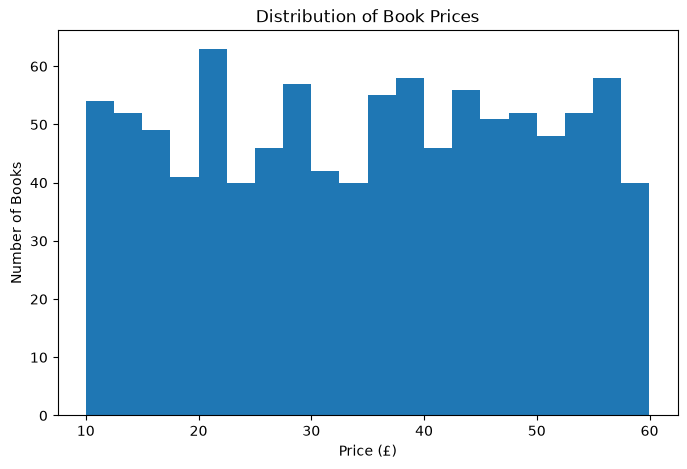

In [170]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean["Price"], bins=20)

plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Prices")

plt.show()

### 3.2 Rating Distribution

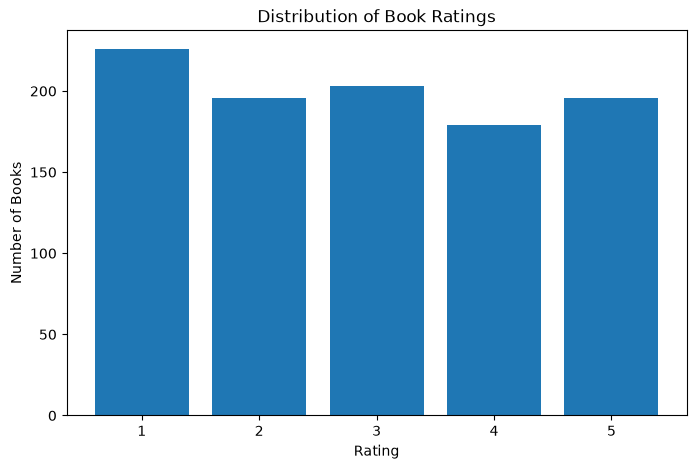

In [171]:
rating_counts = df_clean["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(rating_counts.index, rating_counts.values)

plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Ratings")

plt.xticks([1, 2, 3, 4, 5])

plt.show()

### 3.3 Price Distribution by Rating

<Figure size 800x500 with 0 Axes>

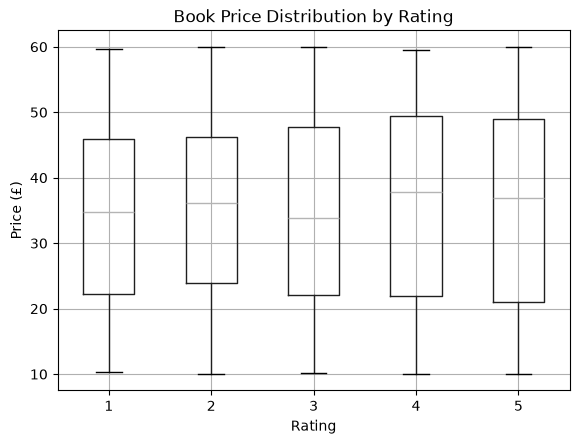

In [172]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(column="Price", by="Rating")

plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.title("Book Price Distribution by Rating")

plt.suptitle("")

plt.show()

### 3.4 Average Price by Category

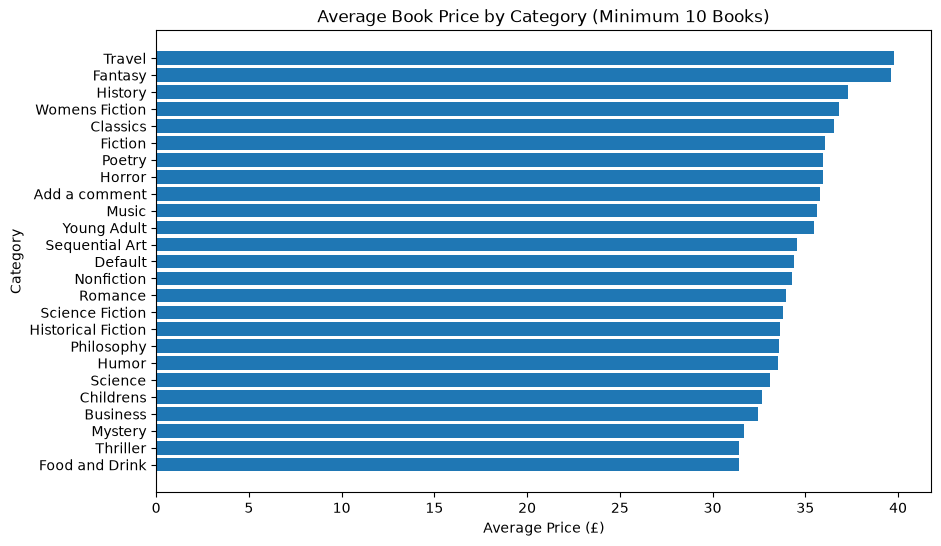

In [173]:
category_plot = (
    df_clean
    .groupby("Category")["Price"]
    .agg(["count", "mean"])
)

category_plot = category_plot[
    category_plot["count"] >= 10
].sort_values("mean", ascending=False)

plt.figure(figsize=(10, 6))

plt.barh(
    category_plot.index,
    category_plot["mean"]
)

plt.xlabel("Average Price (£)")
plt.ylabel("Category")
plt.title("Average Book Price by Category (Minimum 10 Books)")

plt.gca().invert_yaxis()

plt.show()


## Step 4: Hypothesis Testing

Hypothesis testing is performed to determine whether there is a statistically significant difference in average book prices across different rating groups.

Since the dataset contains five independent rating groups (1 to 5), a One-Way ANOVA test is used.

### Hypotheses

**Null Hypothesis (H₀):**  
There is no significant difference in the mean book price across the five rating groups.

**Alternative Hypothesis (H₁):**  
At least one rating group has a significantly different mean book price.

A significance level (α) of 0.05 is used.

If the p-value is less than 0.05, the null hypothesis will be rejected. Otherwise, the null hypothesis will not be rejected.

In [175]:
from scipy.stats import f_oneway

In [176]:
rating_1 = df_clean[df_clean["Rating"] == 1]["Price"]
rating_2 = df_clean[df_clean["Rating"] == 2]["Price"]
rating_3 = df_clean[df_clean["Rating"] == 3]["Price"]
rating_4 = df_clean[df_clean["Rating"] == 4]["Price"]
rating_5 = df_clean[df_clean["Rating"] == 5]["Price"]


In [177]:
f_stat, p_value = f_oneway(
    rating_1,
    rating_2,
    rating_3,
    rating_4,
    rating_5
)

print("F-statistic:", f_stat)
print("p-value:", p_value)

F-statistic: 0.36594095586137154
p-value: 0.8329710147157289


### ANOVA Test Result and Interpretation

The One-Way ANOVA test produced an F-statistic of 0.3659 and a p-value of 0.8330.

Since the p-value (0.8330) is greater than the significance level of 0.05, the null hypothesis is not rejected.

Therefore, there is no statistically significant difference in the mean book prices across the five rating groups.

This suggests that book ratings do not have a statistically significant effect on book prices in this dataset.


## Step 5: Final Data Validation and Export

After completing the exploratory and statistical analysis, the cleaned dataset is validated one final time before being stored in the MySQL database.

The final validation checks for:
- Missing values
- Duplicate records
- Correct data types
- Invalid prices
- Invalid ratings
- Duplicate product identifiers

The validated dataset is then exported as a CSV file for database integration.

In [180]:
df_clean[df_clean["Description"].isnull()][
    ["Product_Name", "Description", "Product_URL"]
]

,Product_Name,Description,Product_URL
160,The Bridge to Consciousness: I'm Writing the B...,NaN,https://books.toscrape.com/catalogue/the-bridg...
995,Alice in Wonderland (Alice's Adventures in Won...,NaN,https://books.toscrape.com/catalogue/alice-in-...


In [181]:
df_clean["Description"] = df_clean["Description"].fillna("Not Available")

In [182]:
df_clean.isnull().sum()

Product_Name         0
Price                0
Rating               0
Availability         0
Category             0
UPC                  0
Number_of_Reviews    0
Description          0
Product_URL          0
dtype: int64

In [183]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate UPCs:", df_clean["UPC"].duplicated().sum())

Duplicate rows: 0
Duplicate UPCs: 0


In [184]:
print("Final dataset shape:", df_clean.shape)

Final dataset shape: (1000, 9)


In [185]:
df_clean.dtypes

Product_Name             str
Price                float64
Rating                 int64
Availability             str
Category                 str
UPC                      str
Number_of_Reviews      int64
Description              str
Product_URL              str
dtype: object

In [186]:
df_clean.to_csv("cleaned_books.csv", index=False)

In [187]:
import os

print("File exists:", os.path.exists("cleaned_books.csv"))

File exists: True


In [188]:
df_final = pd.read_csv("cleaned_books.csv")

print(df_final.shape)
df_final.head()

(1000, 9)


,Product_Name,Price,Rating,Availability,Category,UPC,Number_of_Reviews,Description,Product_URL
0,A Light in the Attic,51.77,3,In stock,Poetry,a897fe39b1053632,0,It's hard to imagine a world without A Light i...,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,Historical Fiction,90fa61229261140a,0,"""Erotic and absorbing...Written with starling ...",https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,Fiction,6957f44c3847a760,0,"Dans une France assez proche de la nÃ´tre, un ...",https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,Mystery,e00eb4fd7b871a48,0,"WICKED above her hipbone, GIRL across her hear...",https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,History,4165285e1663650f,0,From a renowned historian comes a groundbreaki...,https://books.toscrape.com/catalogue/sapiens-a...


### Final Data Validation

The final dataset contains 1,000 book records and 9 variables. Duplicate records and duplicate UPCs were not found. The two missing descriptions were replaced with "Not Available". Price and rating values were validated, and no invalid or negative values were detected.

The final cleaned dataset contains no missing values and is ready for storage in the MySQL database.


## Step 6: Storing Cleaned Data in MySQL

The cleaned e-commerce dataset is stored in a MySQL database for structured storage and further analysis.

A relational table is created to store product information including product name, price, rating, availability, category, UPC, number of reviews, description, and product URL.

The cleaned CSV dataset is then imported into the MySQL database using Python and MySQL Connector.

## Step 6.1: Connecting Python to MySQL

The cleaned book dataset is imported into the MySQL database using the `mysql-connector-python` library.

A connection is established between Python and the MySQL database `ecommerce_books`, and the cleaned records are inserted into the `books` table.


In [189]:
import mysql.connector

In [190]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="",
    database="ecommerce_books"
)

print("MySQL connection successful!")

MySQL connection successful!


In [191]:
import pandas as pd

df_final = pd.read_csv("cleaned_books.csv")

print("Rows:", len(df_final))
print(df_final.head())

Rows: 1000
                            Product_Name  Price  Rating Availability  \
0                   A Light in the Attic  51.77       3     In stock   
1                     Tipping the Velvet  53.74       1     In stock   
2                             Soumission  50.10       1     In stock   
3                          Sharp Objects  47.82       4     In stock   
4  Sapiens: A Brief History of Humankind  54.23       5     In stock   

             Category               UPC  Number_of_Reviews  \
0              Poetry  a897fe39b1053632                  0   
1  Historical Fiction  90fa61229261140a                  0   
2             Fiction  6957f44c3847a760                  0   
3             Mystery  e00eb4fd7b871a48                  0   
4             History  4165285e1663650f                  0   

                                         Description  \
0  It's hard to imagine a world without A Light i...   
1  "Erotic and absorbing...Written with starling ...   
2  Dans une Fra

In [192]:
cursor = conn.cursor()

insert_query = """
INSERT INTO books
(Product_Name, Price, Rating, Availability, Category, UPC,
 Number_of_Reviews, Description, Product_URL)
VALUES (%s, %s, %s, %s, %s, %s, %s, %s, %s)
"""

for _, row in df_final.iterrows():
    cursor.execute(insert_query, (
        row["Product_Name"],
        row["Price"],
        row["Rating"],
        row["Availability"],
        row["Category"],
        row["UPC"],
        row["Number_of_Reviews"],
        row["Description"],
        row["Product_URL"]
    ))

conn.commit()

print("Data inserted successfully!")

Data inserted successfully!


In [193]:
cursor.execute("SELECT COUNT(*) FROM books")

count = cursor.fetchone()[0]

print("Total books in MySQL:", count)

Total books in MySQL: 1000


In [194]:
cursor.execute("""
SELECT Book_ID, Product_Name, Price, Rating, Category
FROM books
LIMIT 10
""")

for row in cursor.fetchall():
    print(row)

(1, 'A Light in the Attic', Decimal('51.77'), 3, 'Poetry')
(2, 'Tipping the Velvet', Decimal('53.74'), 1, 'Historical Fiction')
(3, 'Soumission', Decimal('50.10'), 1, 'Fiction')
(4, 'Sharp Objects', Decimal('47.82'), 4, 'Mystery')
(5, 'Sapiens: A Brief History of Humankind', Decimal('54.23'), 5, 'History')
(6, 'The Requiem Red', Decimal('22.65'), 1, 'Young Adult')
(7, 'The Dirty Little Secrets of Getting Your Dream Job', Decimal('33.34'), 4, 'Business')
(8, 'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull', Decimal('17.93'), 3, 'Default')
(9, 'The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics', Decimal('22.60'), 4, 'Default')
(10, 'The Black Maria', Decimal('52.15'), 1, 'Poetry')


In [195]:
cursor.close()
conn.close()

print("MySQL connection closed.")

MySQL connection closed.


### MySQL Data Import Result

The cleaned dataset containing 1,000 book records was successfully imported into the `books` table in the `ecommerce_books` MySQL database. MySQL automatically generated a unique Book_ID for each record. The imported records were verified using a SQL COUNT query.


### Database Verification

The cleaned dataset was successfully imported into the MySQL `books` table. A SQL COUNT query confirmed that all 1,000 book records were successfully stored. Sample records were also retrieved from the database to verify that the product information was imported correctly.SELECT COUNT(*) AS Total_Books FROM books;

In [196]:
df_clean.columns

Index(['Product_Name', 'Price', 'Rating', 'Availability', 'Category', 'UPC',
       'Number_of_Reviews', 'Description', 'Product_URL'],
      dtype='str')

In [197]:
df_clean.shape

(1000, 9)

In [198]:
df_clean.to_csv("books_final.csv", index=False)

In [199]:
import os
print(os.path.abspath("books_final.csv"))

/Users/syedfarhana/Desktop/Ecommerce_Capstone_Project/Notebooks/books_final.csv


In [204]:
import pandas as pd

df_import = df_clean.copy()

# Replace problematic Unicode characters with closest ASCII equivalents
for col in df_import.select_dtypes(include="object").columns:
    df_import[col] = (
        df_import[col]
        .astype(str)
        .str.encode("ascii", errors="replace")
        .str.decode("ascii")
    )

df_import.to_csv(
    "books_for_mysql.csv",
    index=False,
    encoding="ascii"
)

print(df_import.shape)
print(df_import.isnull().sum())
print("File created successfully")

(1000, 9)
Product_Name         0
Price                0
Rating               0
Availability         0
Category             0
UPC                  0
Number_of_Reviews    0
Description          0
Product_URL          0
dtype: int64
File created successfully


/var/folders/ht/gdjqp6xj5ws0t22rpybm_ztc0000gn/T/ipykernel_1312/1698070383.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_import.select_dtypes(include="object").columns:
